# Learning curves: `run-5.1_baseline-all-feat-purged-5-fold-val-retrain-rand-seed-94086`
Run the cell below once; it refreshes itself until training ends. Top: fold means and the retrain; bottom: each fold's validation curves. A window is final (saved to `plots/`, then shown as a static PNG) once its retrain is done.

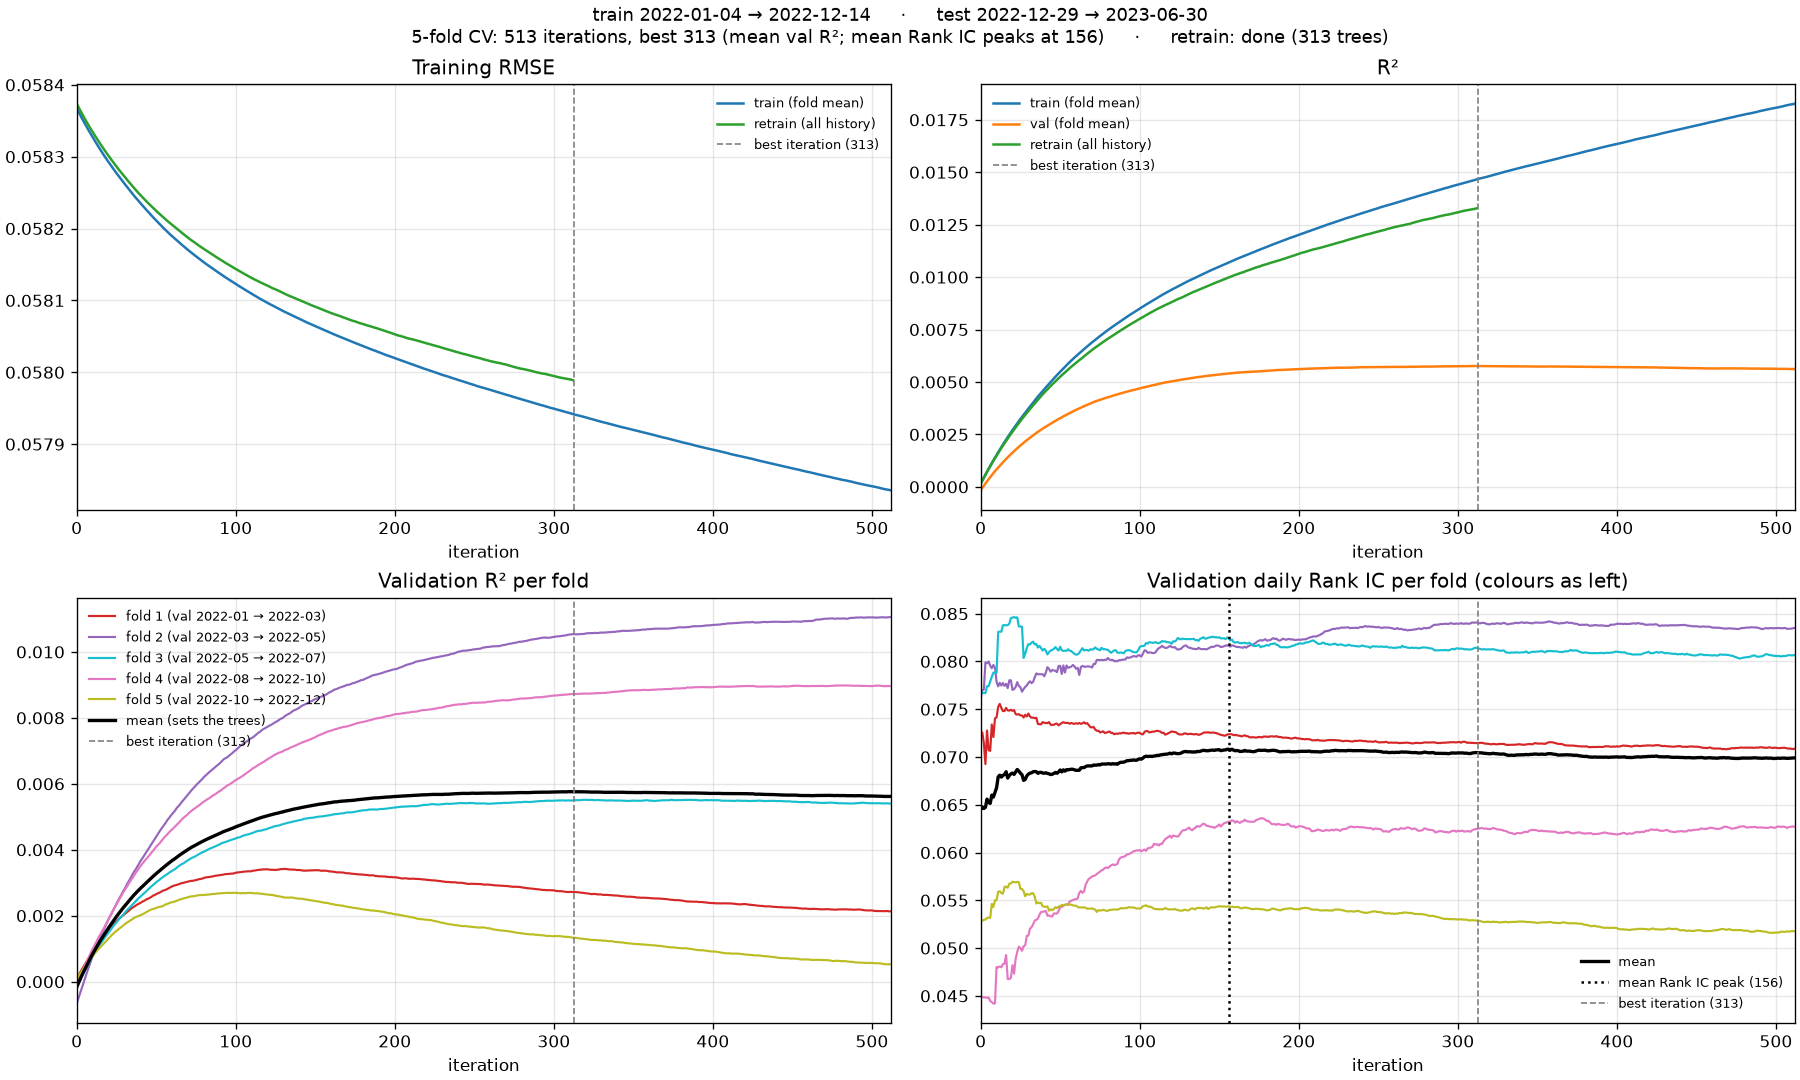

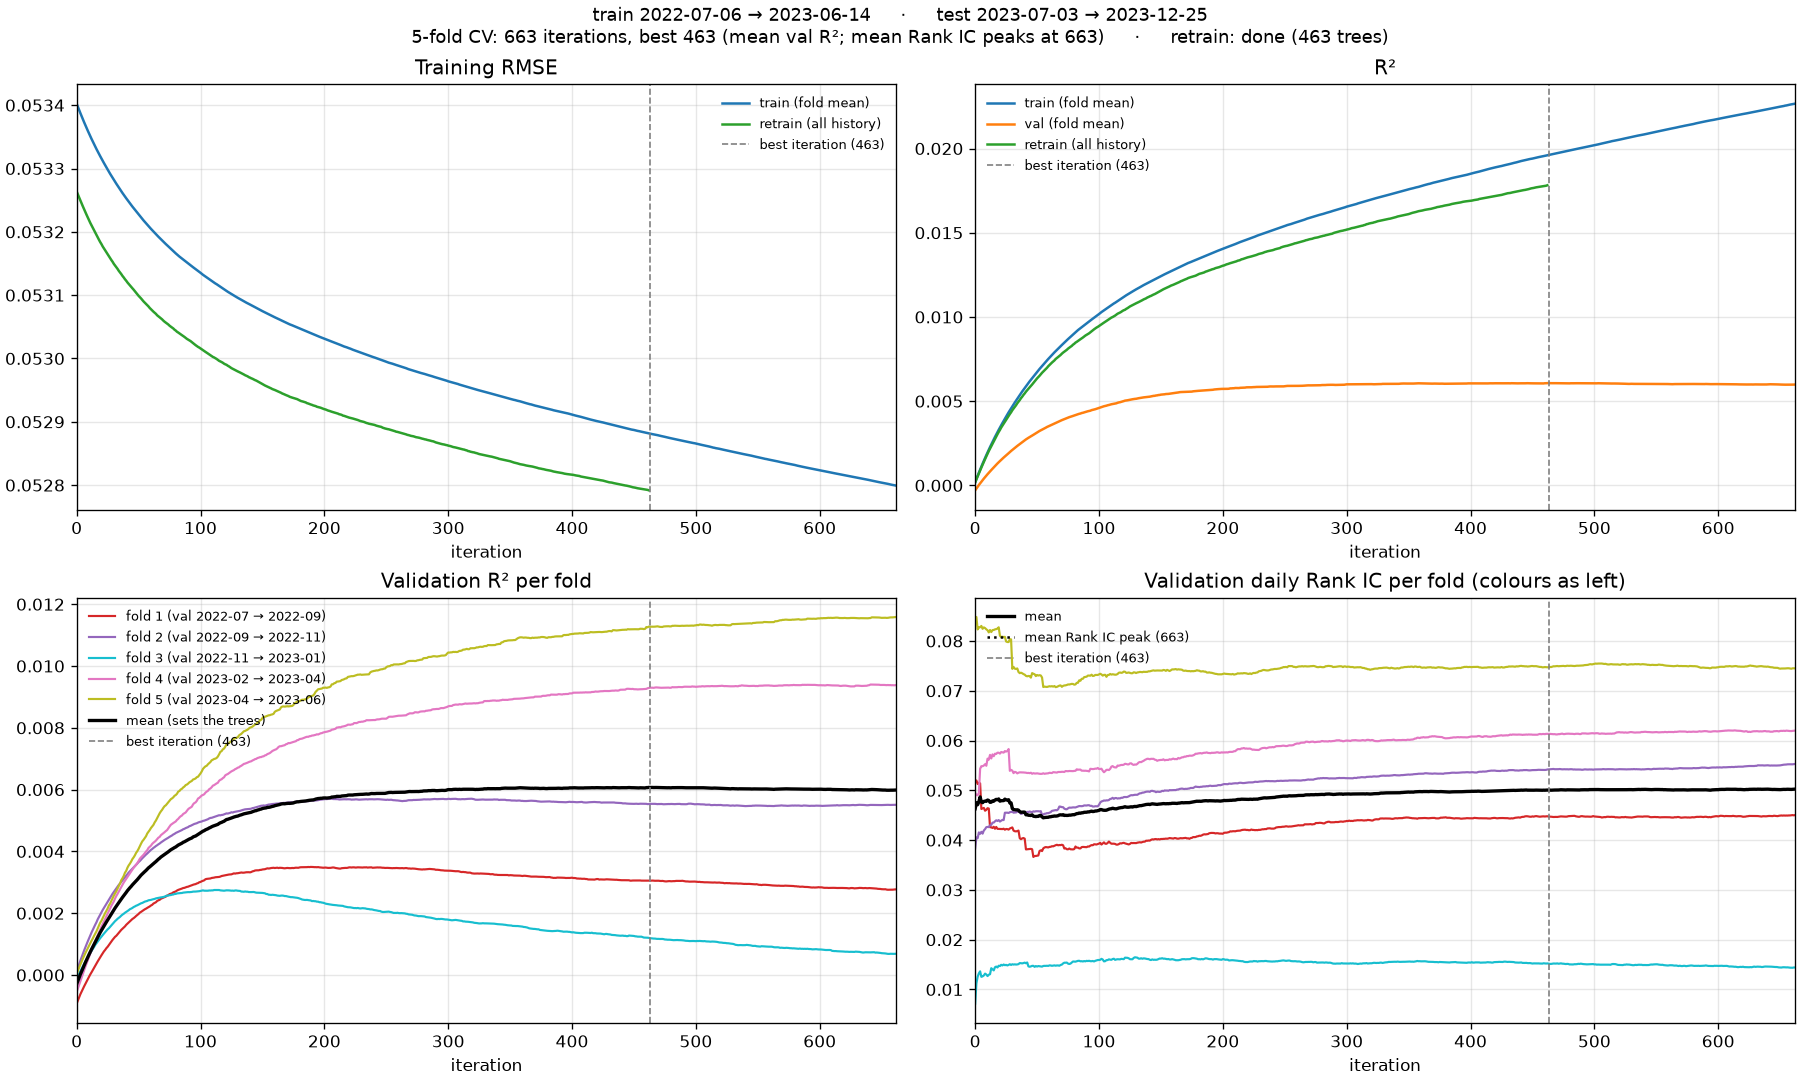

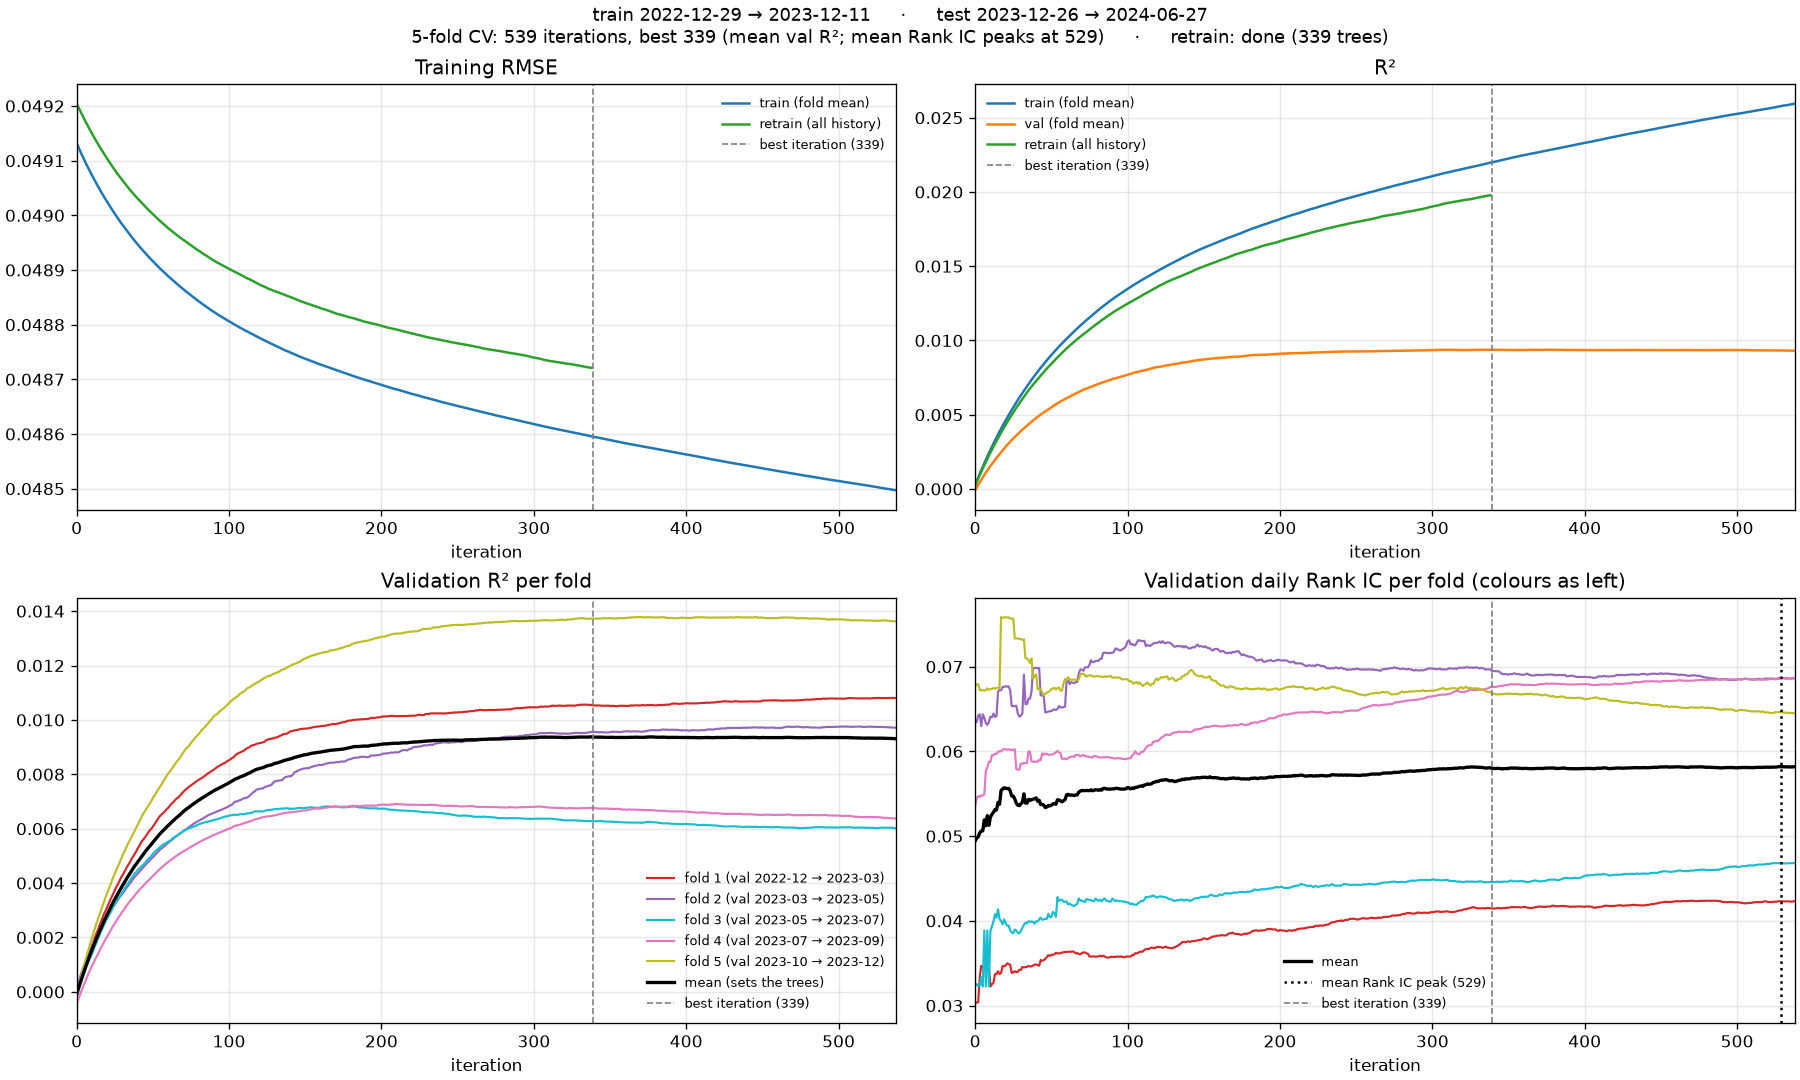

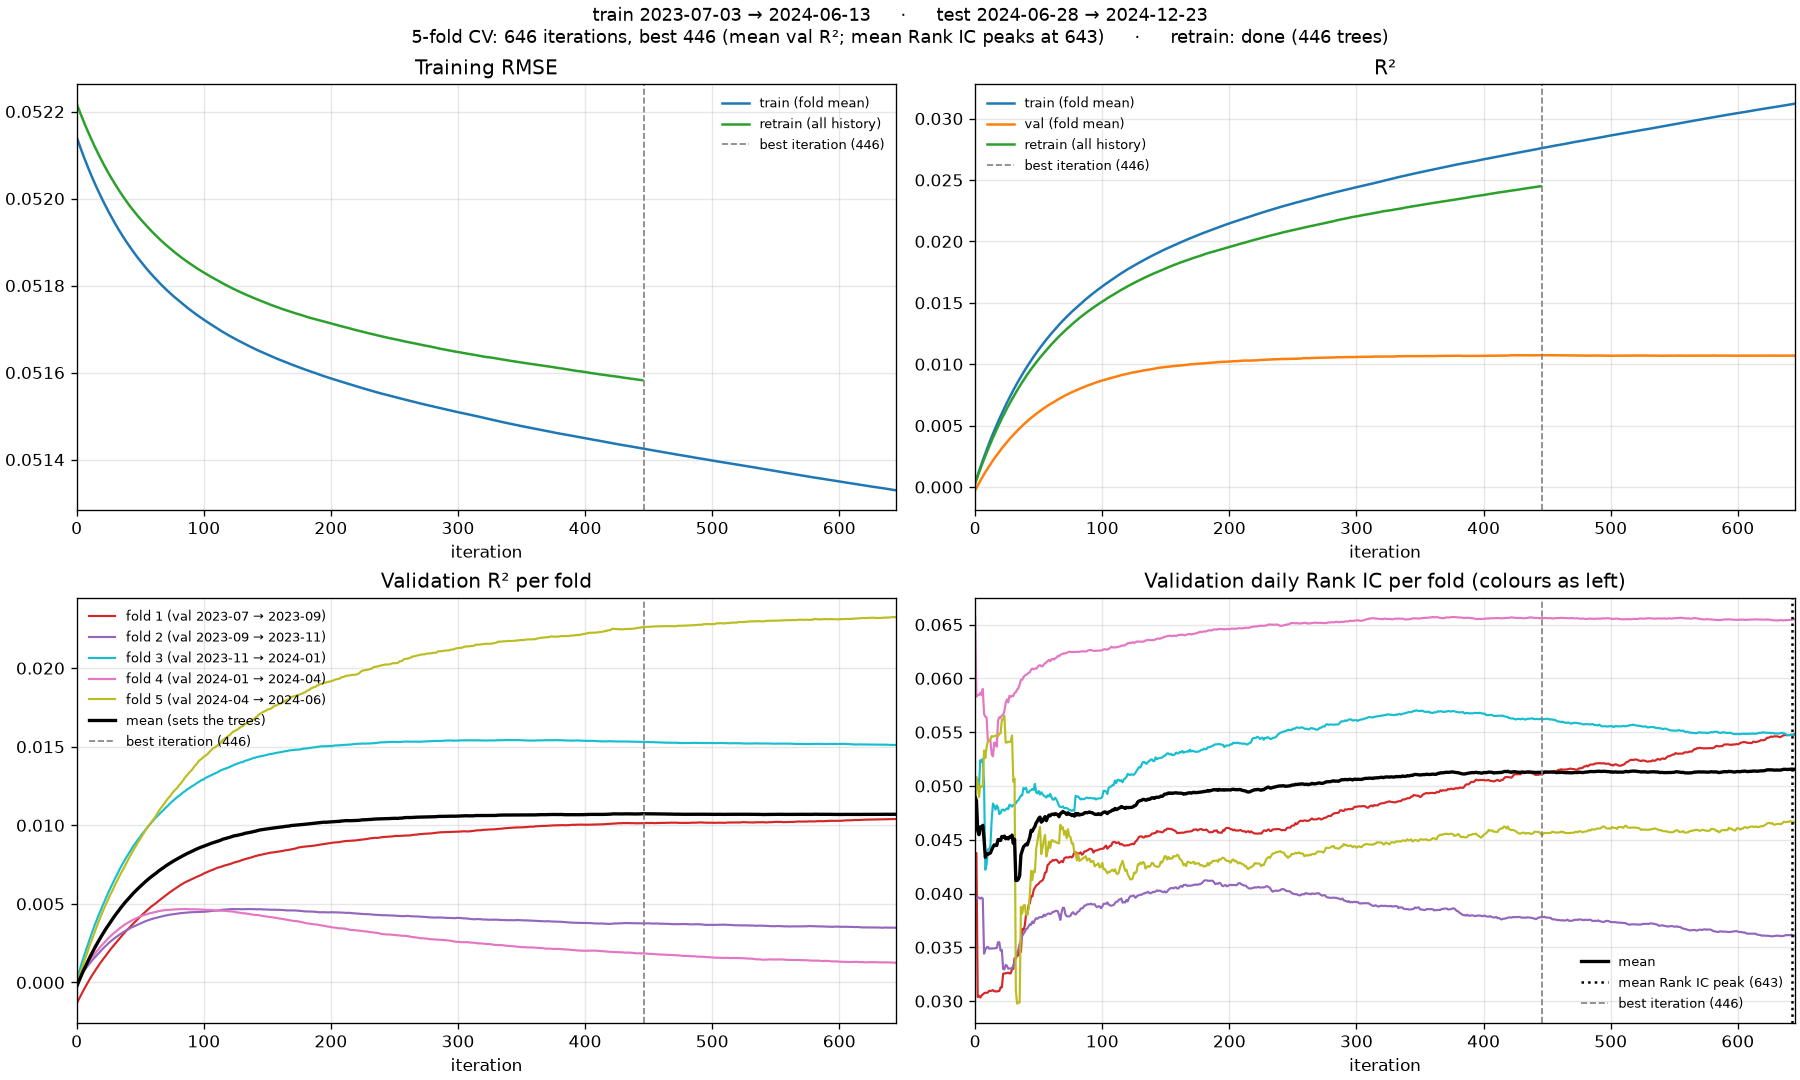

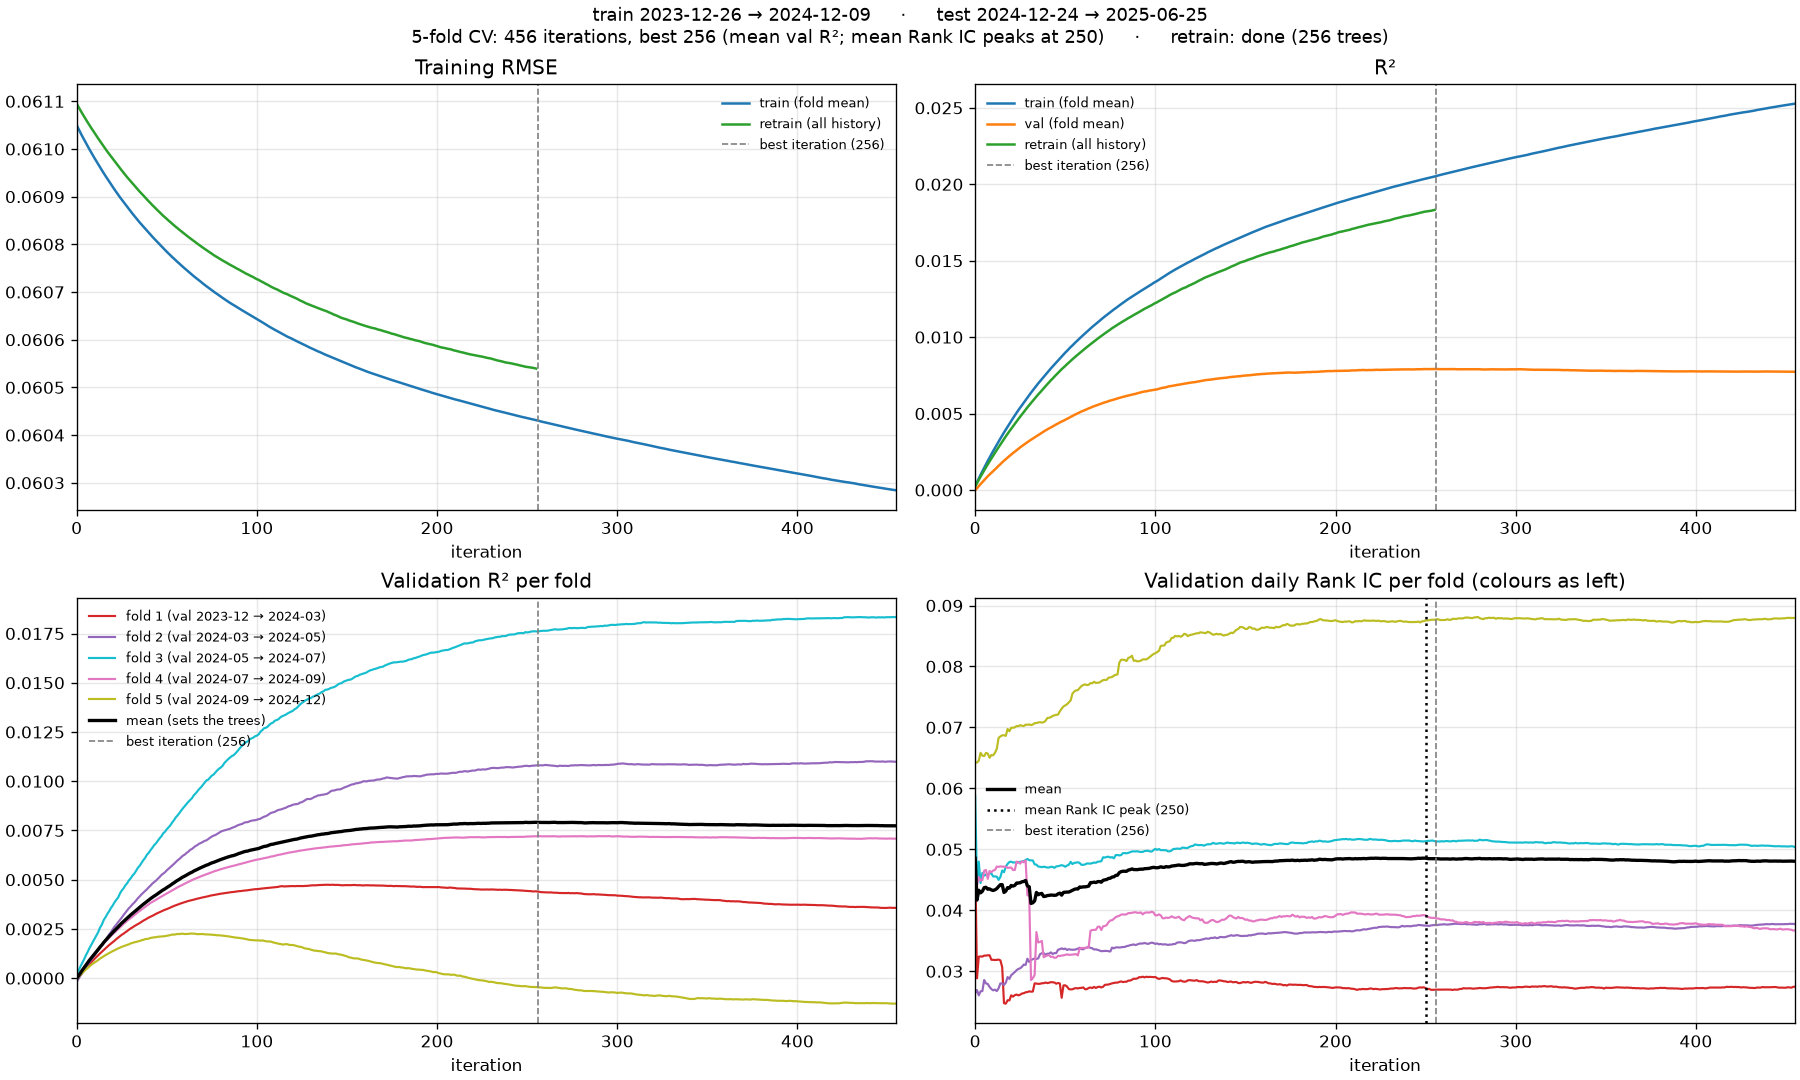

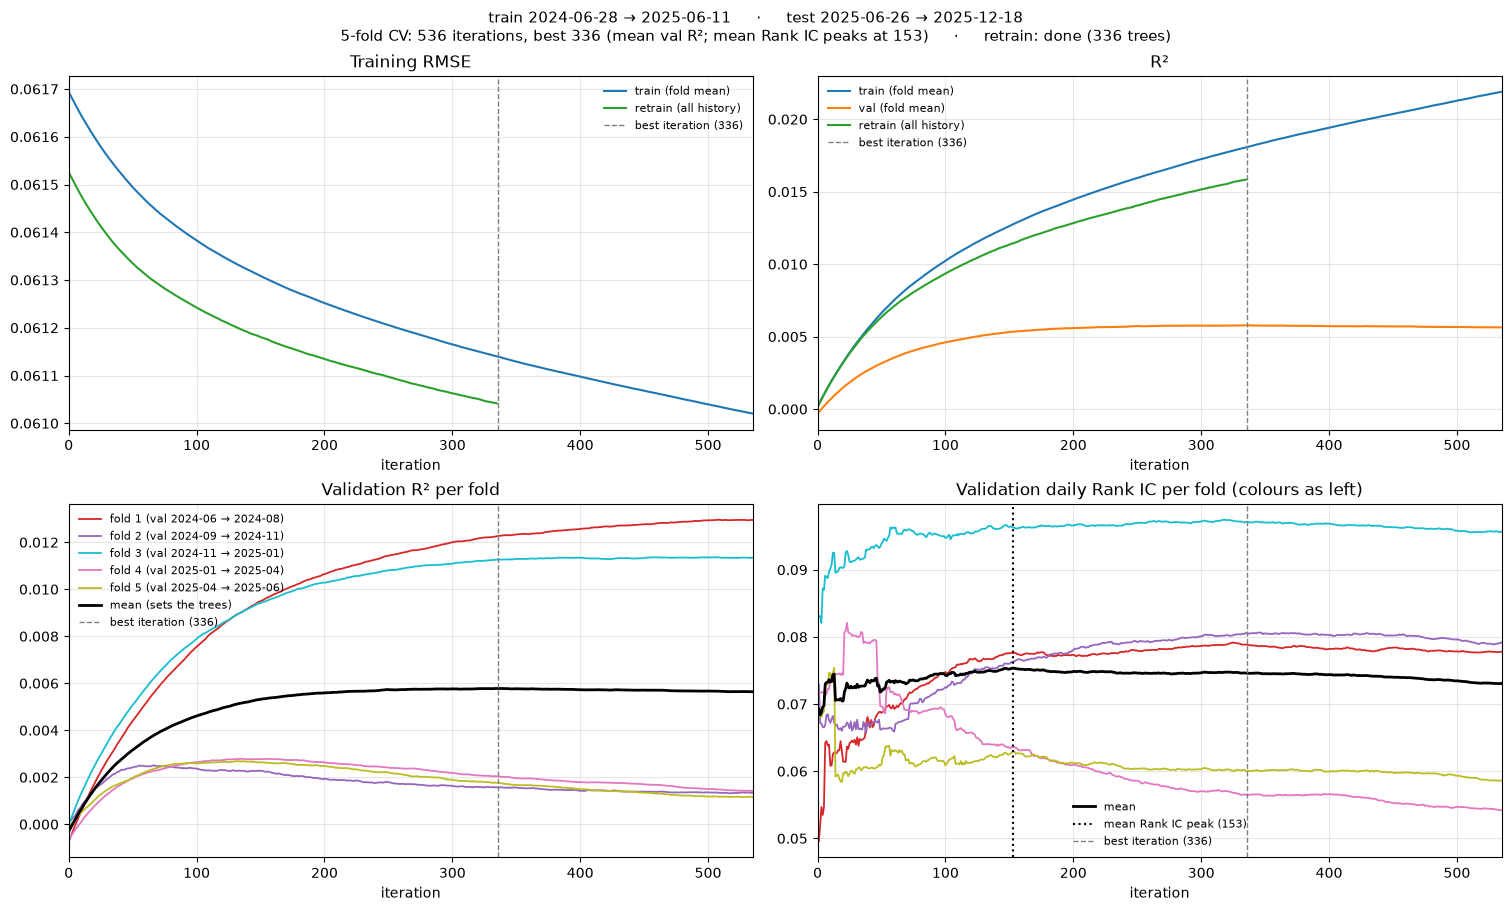

21:51:33: training process has exited. Final plot.


In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, clear_output, display

CURVES_DIR = Path("/workspaces/TimeSeries48/runs/run-5.1_baseline-all-feat-purged-5-fold-val-retrain-rand-seed-94086/curves")
PLOTS_DIR = Path("/workspaces/TimeSeries48/runs/run-5.1_baseline-all-feat-purged-5-fold-val-retrain-rand-seed-94086/plots")   # Finished windows' plots are saved here as PNG.
TRAIN_PID = 771305      # Process ID of the training script.
REFRESH_SECONDS = 3
COLORS = {"train": "C0", "val": "C1", "retrain": "C2"}
FOLD_COLORS = ["C3", "C4", "C9", "C6", "C8", "C5", "C7"]  # Fold k: FOLD_COLORS[k].


def training_alive() -> bool:
    """True while the training process still exists."""
    return Path(f"/proc/{TRAIN_PID}").exists()


def read_json(path: Path) -> dict | None:
    """Read a curves file; None if it doesn't exist yet."""
    try:
        return json.loads(path.read_text())
    except (OSError, json.JSONDecodeError):
        return None


def window_title(stem: str) -> str:
    """'curves_train_A_B_test_C_D' -> 'train A → B  ·  test C → D'."""
    p = stem.removeprefix("curves_").split("_")
    if len(p) == 6:
        return f"train {p[1]} → {p[2]}     ·     test {p[4]} → {p[5]}"
    return stem


def status_line(d: dict, r: dict | None) -> str:
    """Progress of the k-fold and of the retrain."""
    n, best = len(d["curves"]["val"]["r2"]), d["best_iteration"]
    k = len(d.get("folds", {}).get("val_r2", []))
    if best is None:
        return f"{k}-fold CV: {n} iterations so far..."
    cv = (
        f"{k}-fold CV: {n} iterations, best {best} (mean val R²; "
        f"mean Rank IC peaks at {d.get('rank_ic_best')})"
    )
    if r is None:
        return f"{cv}     ·     retrain: starting..."
    if r["done"]:
        return f"{cv}     ·     retrain: done ({r['rounds']} trees)"
    m = len(r["curves"].get("retrain", {}).get("rmse", []))
    return f"{cv}     ·     retrain: {m} / {r['rounds']} iterations..."


def fold_label(k: int, ranges: list) -> str:
    """'fold 2 (val 2022-03 → 2022-05)'."""
    if k < len(ranges):
        return f"fold {k + 1} (val {ranges[k][0][:7]} → {ranges[k][1][:7]})"
    return f"fold {k + 1}"


def draw(f: Path, d: dict, r: dict | None) -> plt.Figure:
    """One window: fold means and per-fold validation curves, retrain overlaid."""
    best, rbest, c = d["best_iteration"], d.get("rank_ic_best"), d["curves"]
    folds, ranges = d.get("folds", {}), d.get("fold_validation", [])
    rc = (r or {}).get("curves", {}).get("retrain", {})
    n = len(c["val"]["r2"])
    fig, axes = plt.subplots(2, 2, figsize=(15, 9), layout="constrained")
    (ax_rmse, ax_r2), (ax_fold, ax_ric) = axes
    ax_rmse.plot(c["train"]["rmse"], c=COLORS["train"], label="train (fold mean)")
    if rc.get("rmse"):
        ax_rmse.plot(rc["rmse"], c=COLORS["retrain"], label="retrain (all history)")
    ax_rmse.set_title("Training RMSE")
    ax_r2.plot(c["train"]["r2"], c=COLORS["train"], label="train (fold mean)")
    ax_r2.plot(c["val"]["r2"], c=COLORS["val"], label="val (fold mean)")
    if rc.get("r2"):
        ax_r2.plot(rc["r2"], c=COLORS["retrain"], label="retrain (all history)")
    ax_r2.set_title("R²")
    for k, values in enumerate(folds.get("val_r2", [])):
        color = FOLD_COLORS[k % len(FOLD_COLORS)]
        ax_fold.plot(values, c=color, lw=1.3, label=fold_label(k, ranges))
    ax_fold.plot(c["val"]["r2"], c="black", lw=2, label="mean (sets the trees)")
    ax_fold.set_title("Validation R² per fold")
    for k, values in enumerate(folds.get("val_rank_ic", [])):
        ax_ric.plot(values, c=FOLD_COLORS[k % len(FOLD_COLORS)], lw=1.3)
    ax_ric.plot(c["val"]["rank_ic"], c="black", lw=2, label="mean")
    if rbest is not None:
        label = f"mean Rank IC peak ({rbest})"
        ax_ric.axvline(rbest, ls=":", lw=1.5, c="black", label=label)
    ax_ric.set_title("Validation daily Rank IC per fold (colours as left)")
    for ax in axes.flat:
        if best is not None:
            label = f"best iteration ({best})"
            ax.axvline(best, ls="--", lw=1, c="gray", label=label)
        ax.set_xlim(0, max(n - 1, 1))  # Set by the k-fold only.
        ax.set_xlabel("iteration")
        ax.ticklabel_format(axis="y", useOffset=False)  # No offset text on top.
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, frameon=False)
    fig.suptitle(f"{window_title(f.stem)}\n{status_line(d, r)}", fontsize=11)
    return fig


def plot_curves() -> None:
    """Show every window; finished ones (retrain done) as their saved PNG."""
    files = sorted(CURVES_DIR.glob("curves_*.json"))
    if not files:
        print("No curves yet: training just started...")
    for f in files:
        d = read_json(f)
        if d is None:
            continue
        rf = f.with_name(f.name.replace("curves_", "retrain_", 1))
        r = read_json(rf)
        png = PLOTS_DIR / f"{f.stem}.png"
        done = r is not None and r["done"]
        # A finished window is drawn and saved once, then shown as a static PNG,
        # unless its curves are newer than the PNG (e.g. after a rerun).
        if done and png.exists() and png.stat().st_mtime >= max(
            f.stat().st_mtime, rf.stat().st_mtime
        ):
            display(Image(filename=str(png)))
            continue
        fig = draw(f, d, r)
        if done:
            PLOTS_DIR.mkdir(parents=True, exist_ok=True)
            fig.savefig(png, dpi=120)  # Before show().
        plt.show()
        plt.close(fig)


# Refresh until the training process exits, then draw a final plot and stop.
# Interrupt the cell (stop button) to end it early; training is unaffected.
while True:
    alive = training_alive()
    clear_output(wait=True)
    plot_curves()
    stamp = time.strftime("%H:%M:%S")
    if not alive:
        print(f"{stamp}: training process has exited. Final plot.")
        break
    print(f"{stamp}: training running (PID {TRAIN_PID})...")
    time.sleep(REFRESH_SECONDS)
